In [1]:
# Importamos las librerías necesarias para desarrollar el proyecto
import numpy as np
import pandas as pd
import seaborn as sns
from math import sqrt
from pprint import pprint
from sklearn import linear_model, metrics
from sklearn.model_selection import (train_test_split,cross_validate,KFold)
from sklearn import preprocessing
from sklearn.feature_selection import (SelectKBest,f_regression)
from sklearn.metrics import make_scorer
import matplotlib.pyplot as plt

import os

In [2]:
# 1) Descargamos automáticamente el conjunto de datos desde Kaggle

!kaggle datasets download -d mirichoi0218/insurance --unzip

print("Dataset descargado correctamente")

Dataset URL: https://www.kaggle.com/datasets/mirichoi0218/insurance
License(s): DbCL-1.0

Dataset descargado correctamente



  0%|          | 0.00/16.0k [00:00<?, ?B/s]
100%|##########| 16.0k/16.0k [00:00<00:00, 1.01MB/s]


In [4]:
# 1.1) Observamos los archivos que existen en la carpeta actual

print("Archivos disponibles:")
print(os.listdir())

Archivos disponibles:
['.ipynb_checkpoints', 'Cuaderno', 'dataset', 'img', 'img.zip', 'insurance.csv', 'Prueba.ipynb']


In [5]:
# 1.2) Leemos el archivo insurance.csv utilizando pandas

df = pd.read_csv("insurance.csv")

print("Dataset cargado correctamente")

Dataset cargado correctamente


In [6]:
# 1.3) Mostramos los primeros registros del dataset

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
# 1.4) Mostramos el número de filas y columnas del dataset

print("Numero de Filas:", df.shape[0])

print("Numero de Columnas:", df.shape[1])

Numero de Filas: 1338
Numero de Columnas: 7


In [8]:
# 1.5) Observamos información general sobre las variables del dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [9]:
# 1.6) Mostramos los nombres de las columnas del dataset

print("Columnas del dataset:")

print(df.columns.tolist())

Columnas del dataset:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


#### EDA Y CALIDAD DE LOS DATOS


In [10]:
# 2) Mostramos las estadísticas descriptivas del dataset

df.describe(include="all")

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


In [11]:
# 2.1) Revisamos si existen valores nulos en cada columna

print("Valores nulos por columna:")

print(df.isnull().sum())

Valores nulos por columna:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [12]:
# 2.2) Revisamos si existen registros duplicados

print("Cantidad de filas duplicadas:",df.duplicated().sum())

Cantidad de filas duplicadas: 1


In [13]:
# 2.3) Eliminamos los registros duplicados encontrados

df = df.drop_duplicates()

print("Datos despues de eliminar datos duplicados:",df.shape)

Datos despues de eliminar datos duplicados: (1337, 7)


In [14]:
# 2.4) Mostramos el tipo de dato de cada variable

print("Tipos de datos:")

print(df.dtypes)

Tipos de datos:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


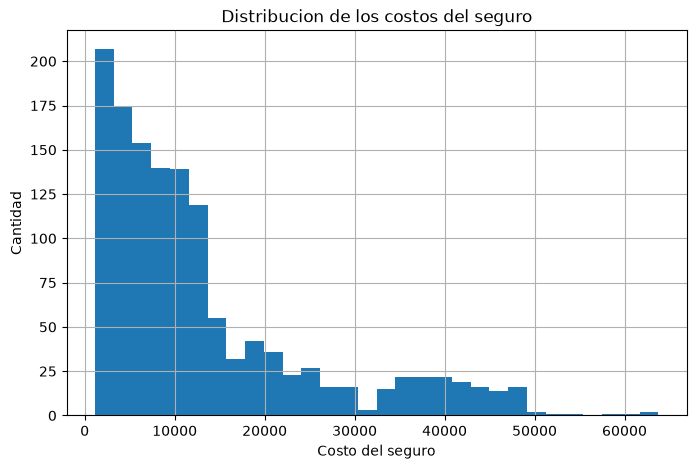

In [17]:
# 2.5) Representamos la distribución de los gastos médicos

plt.figure(figsize=(8,5))

plt.hist(df["charges"],bins=30)
plt.title("Distribucion de los costos del seguro")
plt.xlabel("Costo del seguro")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

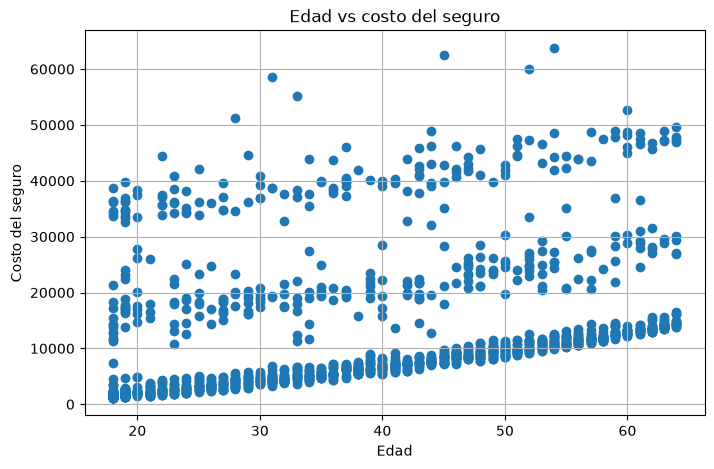

In [18]:
# 2.6) Observamos la relación entre la edad y el costo del seguro

plt.figure(figsize=(8,5))

plt.scatter(df["age"],df["charges"])
plt.title("Edad vs costo del seguro")
plt.xlabel("Edad")
plt.ylabel("Costo del seguro")
plt.grid()
plt.show()

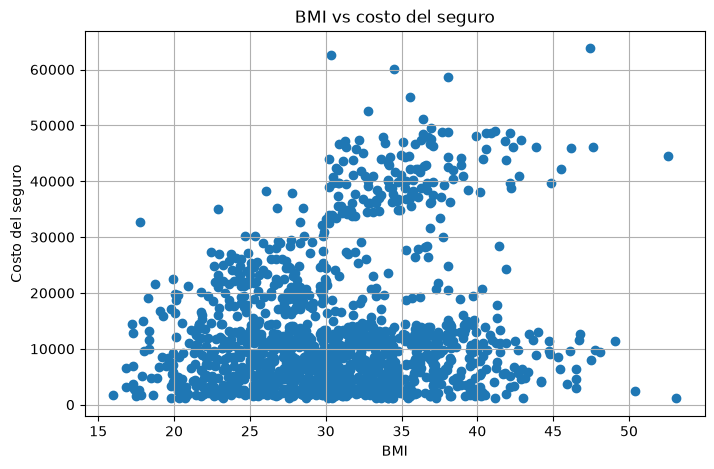

In [19]:
# 2.7) Observamos la relación entre el BMI y el costo del seguro

plt.figure(figsize=(8,5))

plt.scatter(df["bmi"],df["charges"])
plt.title("BMI vs costo del seguro")
plt.xlabel("BMI")
plt.ylabel("Costo del seguro")
plt.grid()
plt.show()

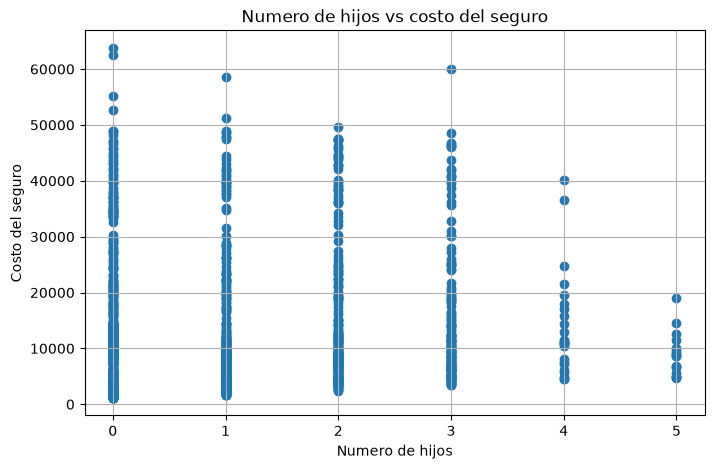

In [20]:
# 2.8) Observamos la relación entre el número de hijos
# y el costo del seguro

plt.figure(figsize=(8,5))
plt.scatter(df["children"],df["charges"])
plt.title("Numero de hijos vs costo del seguro")
plt.xlabel("Numero de hijos")
plt.ylabel("Costo del seguro")
plt.grid()
plt.show()

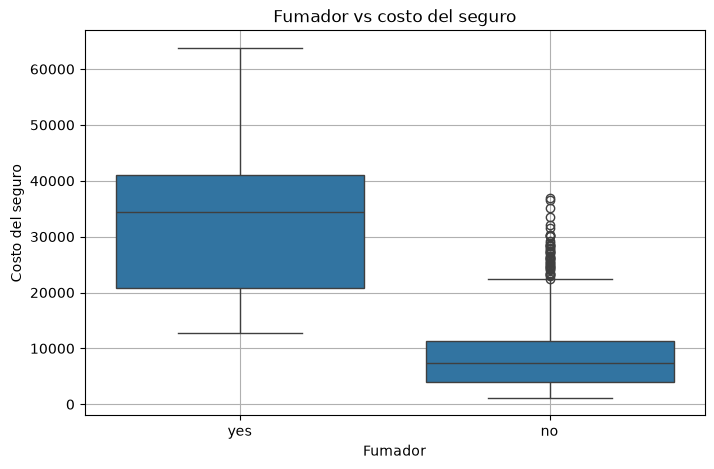

In [21]:
# 2.9) Observamos la distribución de los costos según
# la condición de fumador

plt.figure(figsize=(8,5))

sns.boxplot(data=df,x="smoker",y="charges")
plt.title("Fumador vs costo del seguro")
plt.xlabel("Fumador")
plt.ylabel("Costo del seguro")
plt.grid()
plt.show()

In [23]:
# 2.10) Calculamos la correlación entre las variables numéricas

correlacion = df[["age","bmi","children","charges"]].corr()
print(correlacion)

               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


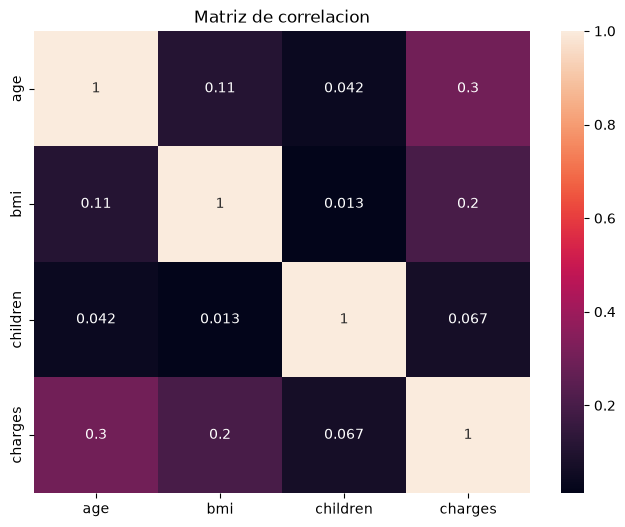

In [24]:
# 2.11) Representamos gráficamente la matriz de correlación

plt.figure(figsize=(8,6))
sns.heatmap(correlacion,annot=True)
plt.title("Matriz de correlacion")
plt.show()

#### DETECCION DE OULIERS

In [25]:
# 3) Definimos las variables numéricas para realizar
# la detección de valores atípicos

variables_numericas = ["age","bmi","children","charges"]
print("Variables numericas:",variables_numericas)

Variables numericas: ['age', 'bmi', 'children', 'charges']


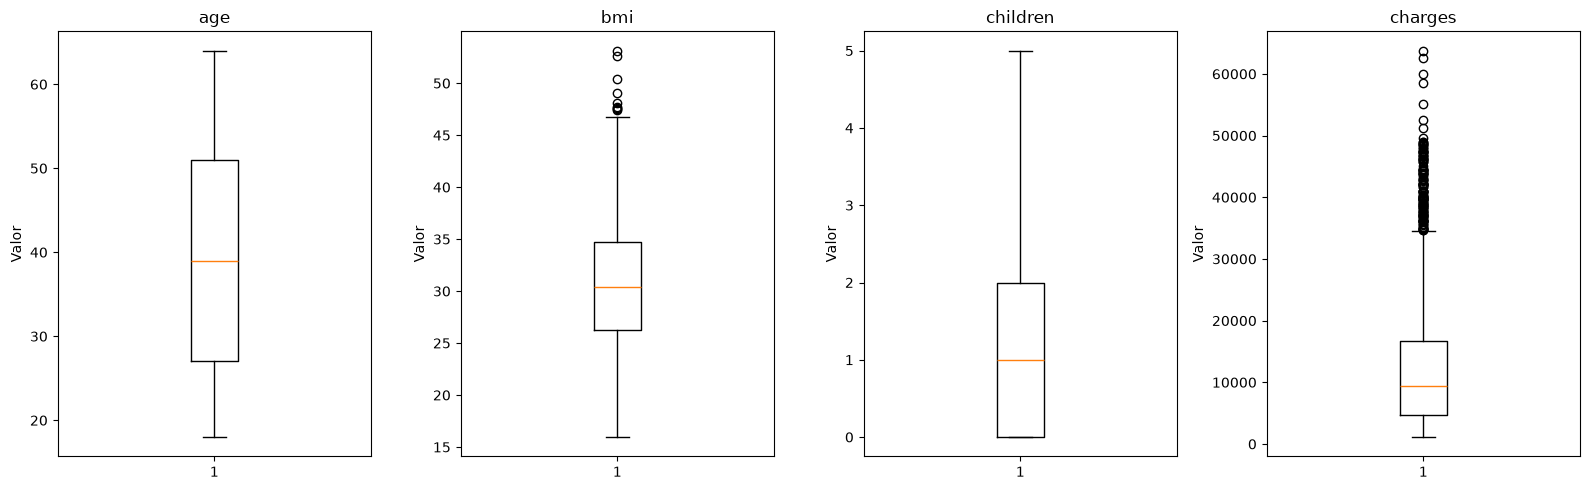

In [26]:
# 3.1) Representamos boxplots para observar los posibles outliers

fig, axes = plt.subplots(1,4,figsize=(16,5))

for i, variable in enumerate(variables_numericas):
    axes[i].boxplot(df[variable])
    axes[i].set_title(variable)
    axes[i].set_ylabel("Valor")
    
plt.tight_layout()
plt.show()

In [28]:
# 3.2) Detectamos los valores atípicos utilizando el método IQR

for variable in variables_numericas:

    # Calculamos el primer cuartil
    Q1 = df[variable].quantile(0.25)
    # Calculamos el tercer cuartil
    Q3 = df[variable].quantile(0.75)
    # Calculamos el rango intercuartílico
    IQR = Q3 - Q1
    
    # Calculamos el límite inferior
    limite_inferior = Q1 - 1.5 * IQR
    # Calculamos el límite superior
    limite_superior = Q3 + 1.5 * IQR

    # Buscamos los valores atípicos
    outliers = df[
        (df[variable] < limite_inferior) |(df[variable] > limite_superior)]

    print("\nVariable:", variable)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Límite inferior:",limite_inferior)
    print("Límite superior:",limite_superior)
    print("Cantidad de outliers:",len(outliers))


Variable: age
Q1: 27.0
Q3: 51.0
IQR: 24.0
Límite inferior: -9.0
Límite superior: 87.0
Cantidad de outliers: 0

Variable: bmi
Q1: 26.29
Q3: 34.7
IQR: 8.410000000000004
Límite inferior: 13.674999999999994
Límite superior: 47.31500000000001
Cantidad de outliers: 9

Variable: children
Q1: 0.0
Q3: 2.0
IQR: 2.0
Límite inferior: -3.0
Límite superior: 5.0
Cantidad de outliers: 0

Variable: charges
Q1: 4746.344
Q3: 16657.71745
IQR: 11911.37345
Límite inferior: -13120.716174999998
Límite superior: 34524.777625
Cantidad de outliers: 139


In [29]:
# 3.3) Los valores atípicos no serán eliminados automáticamente.
# En especial, los valores elevados de charges pueden representar
# gastos médicos reales y aportar información importante al modelo.

print("Los valores atípicos serán conservados para el entrenamiento.")

Los valores atípicos serán conservados para el entrenamiento.


#### PREPARACIÓN DE VARIABLES

In [30]:
# 4) Convertimos las variables categóricas a variables numéricas
# utilizando One-Hot Encoding mediante pandas

df_modelo = pd.get_dummies(df,columns=["sex","smoker","region"],drop_first=True,dtype=int)

print("Columnas después de transformar las variables categóricas:")
print(df_modelo.columns.tolist())

Columnas después de transformar las variables categóricas:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [31]:
# 4.1) Mostramos los primeros registros después
# de transformar las variables categóricas

df_modelo.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [32]:
# 4.2) Separamos las variables independientes X
# de la variable objetivo y

X = df_modelo.drop("charges",axis=1)
y = df_modelo["charges"]

print("Dimensiones de X:",np.shape(X))
print("Dimensiones de y:",np.shape(y))

Dimensiones de X: (1337, 8)
Dimensiones de y: (1337,)


#### PARTICIÓN DE LOS DATOS

In [33]:
# 5) Realizamos la partición externa de los datos
# utilizando 80% para entrenamiento y 20% para prueba

X_training, X_testing, y_training, y_testing = train_test_split(X,y,test_size=0.20,random_state=42)

print("Dimensiones de X_training:",np.shape(X_training))
print("Dimensiones de X_testing:",np.shape(X_testing))
print("Dimensiones de y_training:",np.shape(y_training))
print("Dimensiones de y_testing:",np.shape(y_testing))

Dimensiones de X_training: (1069, 8)
Dimensiones de X_testing: (268, 8)
Dimensiones de y_training: (1069,)
Dimensiones de y_testing: (268,)


#### NORMALIZACIÓN / ESTANDARIZACIÓN

In [34]:
# 6) Creamos el objeto StandardScaler para estandarizar
# las variables de entrada

standardizer = preprocessing.StandardScaler()

In [35]:
# 6.1) Ajustamos el estandarizador únicamente con los datos de entrenamiento

stdr_trained = standardizer.fit(X_training)

In [36]:
# 6.2) Estandarizamos los datos de entrenamiento

X_stdr = stdr_trained.transform(X_training)
print("Dimensiones de X_stdr:",np.shape(X_stdr))

Dimensiones de X_stdr: (1069, 8)


#### SELECCIÓN DE ATRIBUTOS

In [37]:
# 7) Creamos el método SelectKBest para seleccionar
# los atributos que presentan mayor relación con charges

selector = SelectKBest(score_func=f_regression,k=5)

In [38]:
# 7.1) Ajustamos el selector utilizando los datos de entrenamiento

X_training_selected = selector.fit_transform(X_stdr,y_training)

print("Dimensiones después de seleccionar atributos:",np.shape(X_training_selected))

Dimensiones después de seleccionar atributos: (1069, 5)


In [39]:
# 7.2) Mostramos la puntuación obtenida por cada atributo

puntuaciones = selector.scores_

nombres_atributos = X_training.columns

tabla_atributos = pd.DataFrame({"Atributo":nombres_atributos,"Puntuacion":puntuaciones})
tabla_atributos = tabla_atributos.sort_values(by="Puntuacion",ascending=False)

print(tabla_atributos)

           Atributo   Puntuacion
4        smoker_yes  1595.703256
0               age    97.746352
1               bmi    35.091493
2          children     7.982326
6  region_southeast     6.688597
3          sex_male     3.876616
5  region_northwest     3.232139
7  region_southwest     1.384858


In [40]:
# 7.3) Mostramos cuáles fueron los atributos seleccionados

atributos_seleccionados = nombres_atributos[selector.get_support()]

print("Atributos seleccionados:")
print(atributos_seleccionados.tolist())

Atributos seleccionados:
['age', 'bmi', 'children', 'smoker_yes', 'region_southeast']


#### MÉTRICAS DE EVALUACIÓN

In [41]:
# 8) Definimos las métricas que utilizaremos para evaluar el modelo

metricas = {
    "MAE":"neg_mean_absolute_error",
    "RMSE":"neg_root_mean_squared_error",
    "R2":"r2"}

pprint(metricas)

{'MAE': 'neg_mean_absolute_error',
 'R2': 'r2',
 'RMSE': 'neg_root_mean_squared_error'}


#### CONSTRUCCIÓN DEL ALGORITMO

In [42]:
# 9) Construimos el algoritmo de aprendizaje
# utilizando Regresión Lineal

reg = linear_model.LinearRegression(fit_intercept=True)

In [43]:
# 10) Realizamos una validación cruzada interna
# utilizando 5 particiones

cross_val_results = cross_validate(reg,X_training_selected,y_training,
    cv=KFold(n_splits=5,shuffle=True,random_state=42),scoring=metricas)

pprint(cross_val_results)

{'fit_time': array([0.023     , 0.00200057, 0.00200772, 0.00201893, 0.00300241]),
 'score_time': array([0.00200009, 0.00099993, 0.00200939, 0.00296354, 0.00300431]),
 'test_MAE': array([-3867.30366861, -4187.79177344, -4185.65220266, -4410.56543571,
       -4405.63168513]),
 'test_R2': array([0.72889777, 0.71519101, 0.77342684, 0.69218302, 0.70903632]),
 'test_RMSE': array([-5848.52741336, -6002.56104052, -6123.53487604, -6201.36308387,
       -6391.60387483])}


In [44]:
# 10.1) Calculamos los resultados promedio de la validación cruzada

MAE_cv = -cross_val_results["test_MAE"].mean()
RMSE_cv = -cross_val_results["test_RMSE"].mean()
R2_cv = cross_val_results["test_R2"].mean()

print("Resultados de validación cruzada")
print("MAE promedio:",MAE_cv)
print("RMSE promedio:",RMSE_cv)
print("R2 promedio:",R2_cv)

Resultados de validación cruzada
MAE promedio: 4211.388953112332
RMSE promedio: 6113.518057724091
R2 promedio: 0.7237469933086353


#### ENTRENAMIENTO DE LA REGRESIÓN LINEAL

In [45]:
# 11) Entrenamos el modelo utilizando todos los datos
# de entrenamiento que fueron seleccionados

model = reg.fit(X_training_selected,y_training)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [46]:
# 11.1) Obtenemos los coeficientes del modelo de regresión

w = model.coef_
print("Coeficientes del modelo:")
print(w)

Coeficientes del modelo:
[3476.35970927 1903.74875453  637.74881537 9237.0267429  -207.92574546]


In [47]:
# 11.2) Obtenemos el término independiente del modelo

w_0 = model.intercept_
print("Término independiente:",w_0)

Término independiente: 13030.203369289053


In [48]:
# 12) Estandarizamos los datos de prueba utilizando
# el mismo estandarizador entrenado anteriormente

X_test_stdr = stdr_trained.transform(X_testing)

print("Dimensiones de X_test_stdr:",np.shape(X_test_stdr))

Dimensiones de X_test_stdr: (268, 8)


In [49]:
# 12.1) Seleccionamos en los datos de prueba
# los mismos atributos seleccionados durante el entrenamiento

X_test_selected = selector.transform(X_test_stdr)

print("Dimensiones de X_test_selected:",np.shape(X_test_selected))

Dimensiones de X_test_selected: (268, 5)


In [50]:
# 12.2) Realizamos la predicción del conjunto de prueba

y_pred_test = model.predict(X_test_selected)

print("Primeras predicciones:")
print(y_pred_test[:10])

Primeras predicciones:
[ 7865.42247918  6003.50324812 14329.66814526 31817.22155268
  8988.39441086 13183.58668347 30013.10933955  1718.97919929
 10570.28869997 11410.98713417]


In [51]:
# 13) Calculamos las métricas de evaluación del modelo

MAE = metrics.mean_absolute_error(y_testing,y_pred_test)
MSE = metrics.mean_squared_error(y_testing,y_pred_test)
RMSE = sqrt(MSE)
MAPE = metrics.mean_absolute_percentage_error(y_testing,y_pred_test)
R2 = metrics.r2_score(y_testing,y_pred_test)

print("MAE: %.4f" % MAE)
print("MSE: %.4f" % MSE)
print("RMSE: %.4f" % RMSE)
print("MAPE: %.4f" % MAPE)
print("R2: %.4f" % R2)

MAE: 4190.7836
MSE: 35771689.9395
RMSE: 5980.9439
MAPE: 0.4146
R2: 0.8053


#### GRÁFICA REALIDAD VS PREDICCIÓN

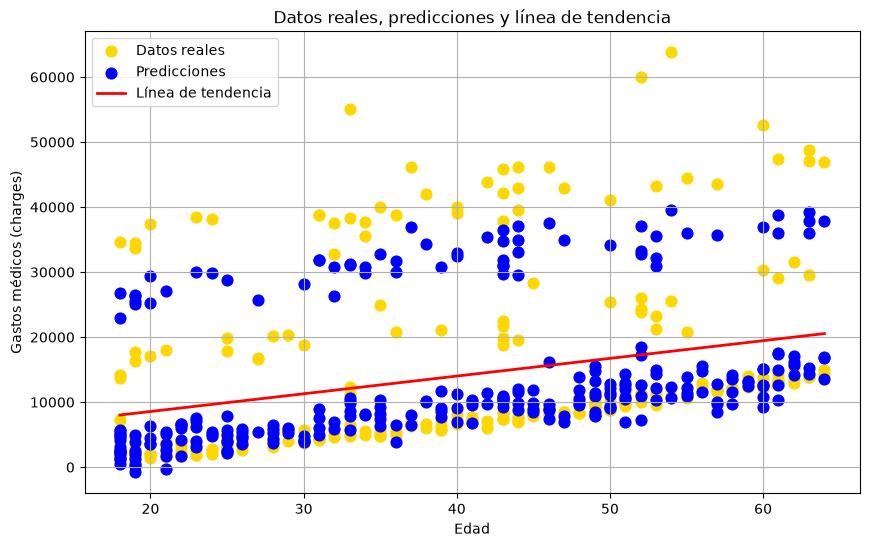

In [58]:
# 14) Gráfica de datos reales, predicciones y línea de tendencia
# Los puntos amarillos representan los datos reales
# Los puntos azules representan las predicciones
# La línea roja representa la tendencia de las predicciones

plt.figure(figsize=(10, 6))

# 1) Datos reales

plt.scatter(X_testing["age"],y_testing,color="gold",s=60,label="Datos reales")

# 2) Predicciones
plt.scatter(X_testing["age"],y_pred_test,color="blue",s=60,label="Predicciones")

# 3) Línea de tendencia de las predicciones
coeficientes = np.polyfit(X_testing["age"],y_pred_test,1)
x_linea = np.linspace(X_testing["age"].min(),X_testing["age"].max(),100)
y_linea = (coeficientes[0] * x_linea + coeficientes[1])
plt.plot(x_linea,y_linea,color="red",linewidth=2,label="Línea de tendencia")

# 4) Configuración de la gráfica

plt.xlabel("Edad")
plt.ylabel("Gastos médicos (charges)")
plt.title("Datos reales, predicciones y línea de tendencia")
plt.legend()
plt.grid()
plt.show()